In [1]:
# Import section
import json

import numpy as np

import matplotlib.pyplot as plt

In [2]:
# Load JSON file
with open('../sketches.json', 'r') as f:
    data = json.load(f)

In [3]:
# Function to select valid strokes
def is_valid_stroke(stroke, epsilon=1e-6):
    x, y, t = stroke
    x = np.array(x)

    if len(x) < 2:
        return False # Stroke too short, need at least one segment
    
    # Calulate the derivative of x
    dx = np.diff(x)

    # Check for strictly increasing x values
    if np.any(dx <= epsilon):
        return False # Vertical or backward stroke detected
    
    return True

In [4]:
# Process the dataset to filter valid strokes and get absolute min and max values
def extract_valid_strokes(data):
    valid_strokes = []
    global_x_min, global_x_max = float('inf'), float('-inf')
    global_y_min, global_y_max = float('inf'), float('-inf')

    for participant_id, participant_data in data.items():
        for sketch_key, sketch in participant_data.items():
            if "attentionTest" in sketch_key:
                continue  # Skip attention test sketches (number 4 drawn by each participant)

            for i, stroke in enumerate(sketch):
                if not is_valid_stroke(stroke):
                    continue  # Skip invalid strokes

                x, y, t = stroke
                x = np.array(x)
                y = -np.array(y) # Invert y-axis

                valid_strokes.append({
                    "participant": participant_id,
                    "sketch": sketch_key,
                    "stroke_index": i,
                    "x": x,
                    "y": y
                })

                # Update global min and max values
                global_x_min = min(global_x_min, x.min())
                global_x_max = max(global_x_max, x.max())
                global_y_min = min(global_y_min, y.min())
                global_y_max = max(global_y_max, y.max())

    return valid_strokes, global_y_min, global_y_max, global_x_min, global_x_max

In [5]:
# Preprocess the whole sketch
def resample_and_normalize(strokes, global_y_min, global_y_max, global_x_min, global_x_max, num_points=512, coverage_threshold=0.3):
    samples_processed = []

    for s in strokes:
        x = s['x']
        y = s['y']

        # Compute coverage
        coverage = (x.max() - x.min()) / (global_x_max - global_x_min)

        #if coverage >= coverage_threshold: # complete melodic contour
        # Resample to fixed number of points
        new_x = np.linspace(x.min(), x.max(), num_points)
        new_y = np.interp(new_x, x, y)
        # Normalize y to [-1, 1] using global min and max
        contour = 2 * (new_y - global_y_min) / (global_y_max - global_y_min) - 1
        # Normalize x to [0, num_points]
        new_x = np.linspace(0, num_points, num_points)

        """
        else: # short curve
            # Preserve duration and location
            active_points = int(num_points * coverage) # number of points to represent the stroke
            # Resample to active points
            new_x = np.linspace(x.min(), x.max(), active_points)
            new_y = np.interp(new_x, x, y)
            # Normalize y to [-1, 1] using global min and max
            new_y = 2 * (new_y - global_y_min) / (global_y_max - global_y_min) - 1
            # Start and end in global x
            start = int((x.min() - global_x_min) / (global_x_max - global_x_min) * num_points)
            end = start + active_points
            # Mask the y values
            contour = np.full(num_points, np.nan) # initialize with NaNs
            contour[start:end] = new_y
            # Normalize x to [0, num_points]
            new_x = np.linspace(0, num_points, num_points)
        """
        
        samples_processed.append({
            **s,
            "new_x": new_x, # normalized x
            "contour": contour, # normalized y
            "coverage": coverage
        })

    return samples_processed

In [6]:
strokes, global_y_min, global_y_max, global_x_min, global_x_max = extract_valid_strokes(data)
print(f"Total valid strokes: {len(strokes)}")
print(f"Global Y Min: {global_y_min}, Global Y Max: {global_y_max}")
print(f"Global X Min: {global_x_min}, Global X Max: {global_x_max}")

samples = resample_and_normalize(strokes, global_y_min, global_y_max, global_x_min, global_x_max)
print(f"Total processed samples: {len(samples)}")

Total valid strokes: 967
Global Y Min: -837, Global Y Max: 59
Global X Min: 0, Global X Max: 1932
Total processed samples: 967


In [7]:
# Get one sketch and preprocess it
participant_id = "5d7513fbad0dbc00010f8fa8"
sound_id = "45510d0bf313673eb95ae4547f32f049"
sketch_key = f"drawingInterface_{sound_id}"

# Get raw sketch
raw_sketch = data[participant_id][sketch_key]

# Get processed strokes for this sketch
valid_strokes = [
    s for s in samples
    if s["sketch"] == sketch_key and s["participant"] == participant_id
]

0.2458592132505176
0.2567287784679089
0.275879917184265


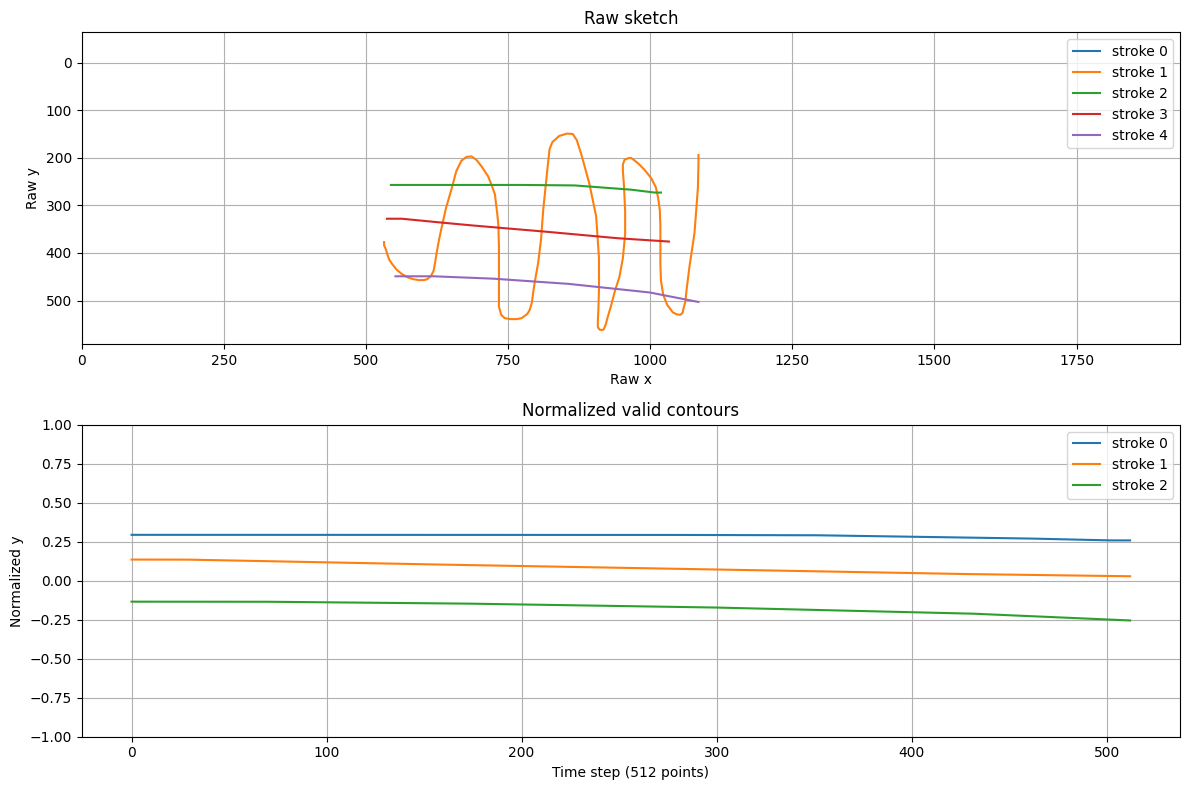

In [9]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 1, 1)
for i, stroke in enumerate(raw_sketch):
    x, y, t = stroke
    plt.plot(x, y, label=f"stroke {i}")

plt.gca().invert_yaxis()  # important: screen coordinates → visual intuition
plt.xlabel("Raw x")
plt.ylabel("Raw y")
plt.title("Raw sketch")
#plt.ylim(-global_y_max, -global_y_min)
plt.xlim(global_x_min, global_x_max)
plt.legend()
plt.grid(True)

plt.subplot(2, 1, 2)
for i, sample in enumerate(valid_strokes):
    print(sample["coverage"])
    plt.plot(sample["new_x"], sample["contour"], label=f"stroke {i}")
plt.xlabel("Time step (512 points)")
plt.ylabel("Normalized y")
plt.title("Normalized valid contours")
plt.ylim(-1, 1)
#plt.xlim(0, 512)
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Preprocess the samples